The goal of this notebook is to plot the criticality values over the time passed since the anesthesia of CA2. As I named and stored the result files badly, I will first do it for one animal.

First, I need the exact time point of the DREADD-injection on the animal. The anesthesia reaches its maximum about 1h after injection. (I asked hongshen and he told me that the CNO-folder in each recording day is recorded right after the injection.)

In [2]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get all filenames in the directory
all_spiketrains= os.listdir('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/extracted_spike_trains/')
ALL_RESULTS = os.listdir('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/mr_estimator_results/')


def create_result_dict(filtered_files):
    """
    for a list of filtered files, collect all corresponding result files and extract the start time
    """
    
    result_dict = {}

    for filename in filtered_files:
        start_time = np.load('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/extracted_spike_trains/' + filename)[0]
        
        
        
        key = '_'.join(filename.split('_')[:3] + filename.split('_')[4:])
        
        # Get the corresponding result files for each key
        result_files = [result for result in ALL_RESULTS if key in result]
        
        # Store the result files in the dictionary
        result_dict[key] = [start_time/1000000, result_files] #us to ms
    return result_dict

def create_result_df(result_dict, cno_time):
    data = []

    for key, value in result_dict.items():
        for result_file in value[1]:
            onset_time = (value[0] + int(result_file.split('_')[5].split('.')[0]) * 90) - cno_time
            # Extract tau and task from the result file name 
            result_df = pd.read_parquet('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/mr_estimator_results/' + result_file)
            tau = result_df['tau'][0]
            m = result_df['branching_factor'][0]
            task = result_file.split('_')[2]
            distance_criticality = -1/np.log(1-m)
            data.append([onset_time, tau, task, distance_criticality])

    # Create the DataFrame
    df_results = pd.DataFrame(data, columns=['onset_time', 'tau', 'task', 'distance_criticality'])
    return df_results

def create_plot(df_results, area: str):
    # Create a scatter plot with color groups based on 'task'
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=df_results, x='onset_time', y='distance_criticality', hue='task', palette='tab10')

    # Fit a non-linear trend line using a polynomial regression
    # Generate a smooth range of x values for a precise trend line
    x_smooth = np.linspace(df_results['onset_time'].min(), df_results['onset_time'].max(), 500)
    z = np.polyfit(df_results['onset_time'], df_results['distance_criticality'], 3)  # 3rd degree polynomial
    p = np.poly1d(z)
    plt.plot(x_smooth, p(x_smooth), color='black', label='Trend Line')

    # Calculate and display the mean for each group
    group_means = df_results.groupby('task')['distance_criticality'].mean()
    for task, mean in group_means.items():
        x_position = df_results[df_results['task'] == task]['onset_time'].iloc[0]  # Use the first x-position from the group
        color = sns.color_palette('tab10')[df_results['task'].unique().tolist().index(task)]  # Get the color for the group
        plt.scatter(x_position, mean, color=color, marker='x', zorder=5)
        # Add horizontal grid lines for better readability

    plt.grid(axis='y', linestyle='--', alpha=0.7, zorder=0)
    # Customize the plot
    plt.title(f'Tau in {area} vs injection time of cno')
    plt.xlabel('Onset Time')
    plt.ylabel('Distance Criticality')	
    plt.legend(title='Task', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()

    plt.show()

Now, create a dict where for each filename, there is a list of result files

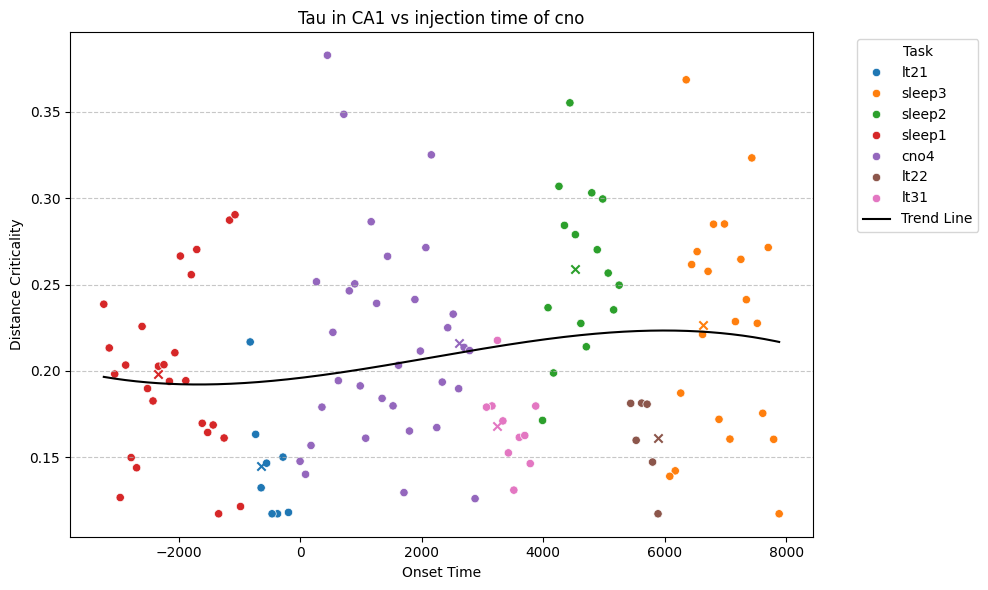

In [ ]:
# choose the animal / day / area combination of interest (in some cases, there will be stuff like CA3b which you need to edit)
filtered_files = [f for f in all_spiketrains if 'model572_d18' in f and '_CA1_' in f]

# rough time of cno injection, best extracted manually (also converted to seconds)
cno_time = np.load('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/extracted_spike_trains/model572_d18_cno4_tt3_CA1_post.npy')[0]/1000000

result_dict = create_result_dict(filtered_files)
df_results = create_result_df(result_dict, cno_time)

create_plot(df_results, 'CA1')

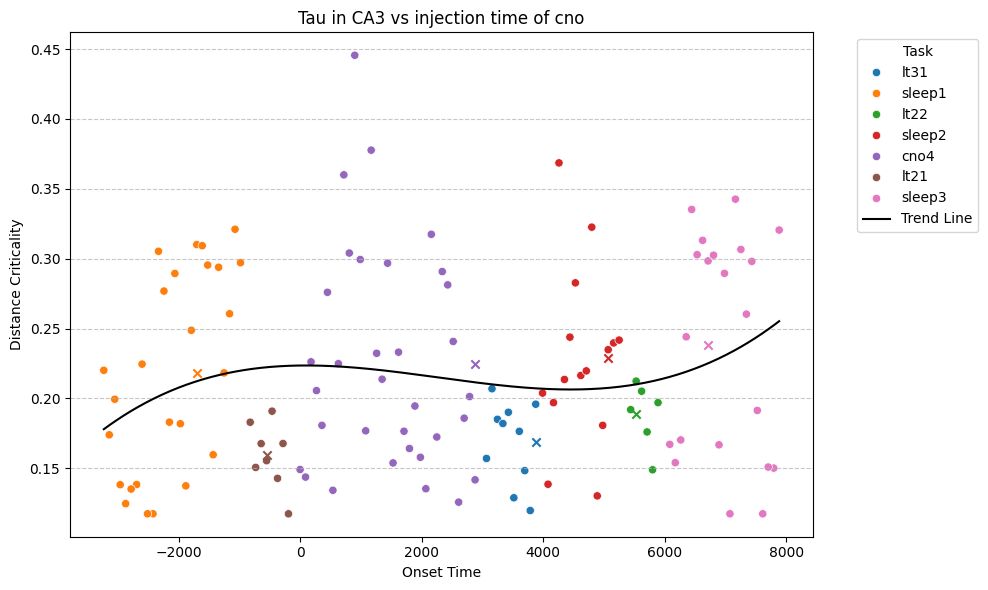

In [7]:
# choose the animal / day / area combination of interest (in some cases, there will be stuff like CA3b which you need to edit)
filtered_files = [f for f in all_spiketrains if 'model572_d18' in f and '_CA3' in f]

# rough time of cno injection, best extracted manually (also converted to seconds)
cno_time = np.load('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/extracted_spike_trains/model572_d18_cno4_tt3_CA1_post.npy')[0]/1000000

result_dict = create_result_dict(filtered_files)
df_results = create_result_df(result_dict, cno_time)

create_plot(df_results, 'CA3')

In [ ]:
# choose the animal / day / area combination of interest (in some cases, there will be stuff like CA3b which you need to edit)
filtered_files = [f for f in all_spiketrains if 'model572_d18' in f and '_CA1_' in f]

# rough time of cno injection, best extracted manually (also converted to seconds)
cno_time = np.load('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/extracted_spike_trains/model1216_d10_cno4_tt3_CA1_post.npy')[0]/1000000

result_dict = create_result_dict(filtered_files)
df_results = create_result_df(result_dict, cno_time)

create_plot(df_results, 'CA1')